# 02 — Day-ahead load forecasting: baselines (SeasonalNaive, LightGBM, ONS)

**Task.** Forecast issued at **D-1 12:00** with data up to 11:00, for the 24 hours of D (steps 13–36),
the same information set as the **ONS programmed load**, which is the external benchmark.
`ONS_adj` is the programmed load rescaled to the curva-carga level with a ratio known at D-1 (causal).

**Backtest.** Rolling origin, one cutoff per day; train from 2015, test from 2024-01-01 to the last
full day (includes the 2026 World Cup). LightGBM refits every 30 days. Point models get causal
rolling conformal intervals.

> ⚠️ This notebook uses **LightGBM** and must not import torch (macOS libomp clash). The deep models
> are in `03_forecast_deep.ipynb`; the final comparison there reads the backtests stored here.

Results are cached in `data/interim/forecasts/<name>.parquet`; set `RETRAIN = True` to refit.
Runtime on an M4: ~10–15 min for SE/CO.

In [1]:
%matplotlib inline
import pandas as pd

from ons_energy.forecast.backtest import last_full_day, mase_scales, run_or_load
from ons_energy.forecast.config import BacktestConfig, ModelSpec
from ons_energy.forecast.evaluate import attach_day_types, dm_table, evaluate_backtest
from ons_energy.tracking import log_backtest
from ons_energy.viz import forecast_plots as F

pd.set_option("display.precision", 3)
RETRAIN = False  # True: refit even if a stored backtest exists
LOG_MLFLOW = True
RUN_WEATHER_ABLATION = False  # global LightGBM on 4 subsystems x 3 weather scenarios (~1 h)

## Experiment

In [2]:
NAIVE = ModelSpec(name="SeasonalNaive", kind="seasonal_naive", params={"season_length": 168})
LGBM = ModelSpec(name="LightGBM", kind="lgbm")
ONS = ModelSpec(name="ONS", kind="ons_programmed")

cfg = BacktestConfig(
    name="mvp_seco_baselines",
    subsystems=["SE"],
    weather="none",
    refit_every_days=30,
    models=[NAIVE, LGBM, ONS],
)
cfg

BacktestConfig(name='mvp_seco_baselines', subsystems=['SE'], train_start=datetime.date(2015, 1, 1), eval_start=datetime.date(2024, 1, 1), test_end=None, origin_hour=12, horizon=36, eval_steps=(13, 36), calib_days=90, refit_every_days=30, weather='none', quantiles=[0.05, 0.1, 0.5, 0.9, 0.95], conformal_window_days=90, accelerator='mps', seed=42, models=[ModelSpec(name='SeasonalNaive', kind='seasonal_naive', params={'season_length': 168}), ModelSpec(name='LightGBM', kind='lgbm', params={}), ModelSpec(name='ONS', kind='ons_programmed', params={})])

In [3]:
cv = run_or_load(cfg, retrain=RETRAIN)
tabs = evaluate_backtest(cv, mase_scales(cfg), reference="ONS")
if LOG_MLFLOW:
    log_backtest(cfg, tabs, cv)
print(f"{cv.target_date.min()} -> {cv.target_date.max()}, {cv.target_date.nunique()} days")
tabs["overall"].sort_values("MAPE")

2026-10-15 21:40:38 | INFO | ons_energy.forecast.backtest | mvp_seco_baselines: 1 series, 103296 rows, 1107 windows (2023-10-03 -> 2026-10-13), weather=none (fallback share 0.0%)
/Users/falcone/Desktop/github-repos/ONS-data-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-15 21:40:39 | INFO | ons_energy.forecast.backtest | mvp_seco_baselines: seasonal_naive done in 0.9s
2026-10-15 21:44:57 | INFO | ons_energy.forecast.backtest | mvp_seco_baselines: lgbm done in 258.3s
2026/10/15 21:45:03 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/15 21:45:03 INFO mlflow.store.db.utils: Updating database tables


2024-01-01 -> 2026-10-13, 1017 days


,model,n_days,MAPE,sMAPE,RMSE,MAE,MASE,pinball,cov80,cov90,width90
3,ONS_adj,1016,2.459,2.476,1434.825,1097.575,0.590,246.542,0.773,0.871,3883.922
2,ONS,1016,2.721,2.674,1595.546,1192.435,0.641,251.805,0.767,0.868,3902.321
1,LightGBM,1017,3.232,3.198,2001.964,1443.174,0.776,366.225,0.780,0.871,5846.916
0,SeasonalNaive,1017,5.359,5.342,3166.238,2359.422,1.269,614.588,0.784,0.863,9842.422


## Actual vs predicted
Whole test period (daily means and 7-day rolling MAPE), then hourly zooms on a normal week and on
special days.

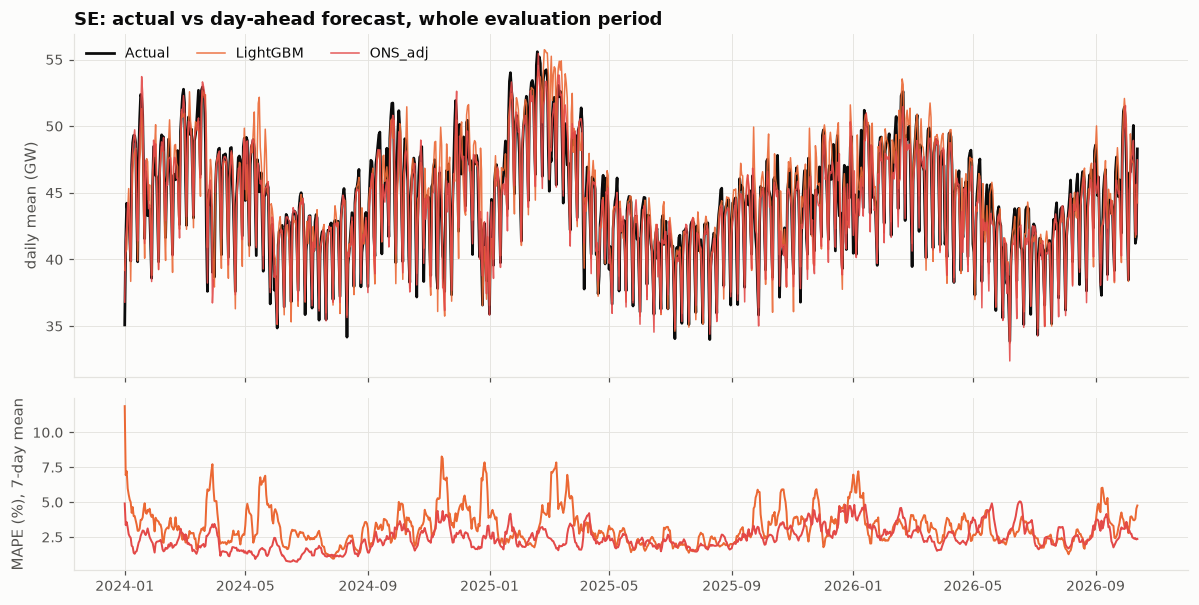

In [4]:
MODELS = ["SeasonalNaive", "LightGBM", "ONS_adj"]
fig = F.actual_vs_forecast_daily(cv, ["LightGBM", "ONS_adj"])

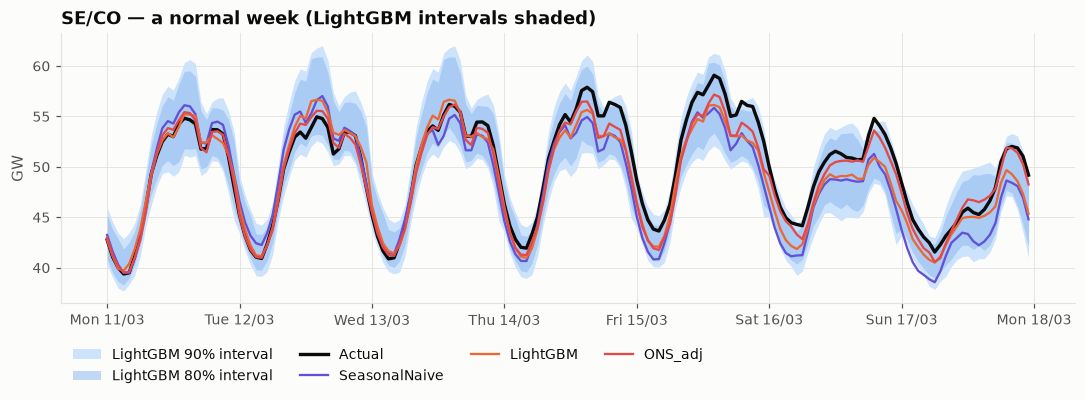

In [5]:
fig = F.actual_vs_forecast(cv, MODELS, "2024-03-11", band_model="LightGBM", title="SE/CO — a normal week (LightGBM intervals shaded)")

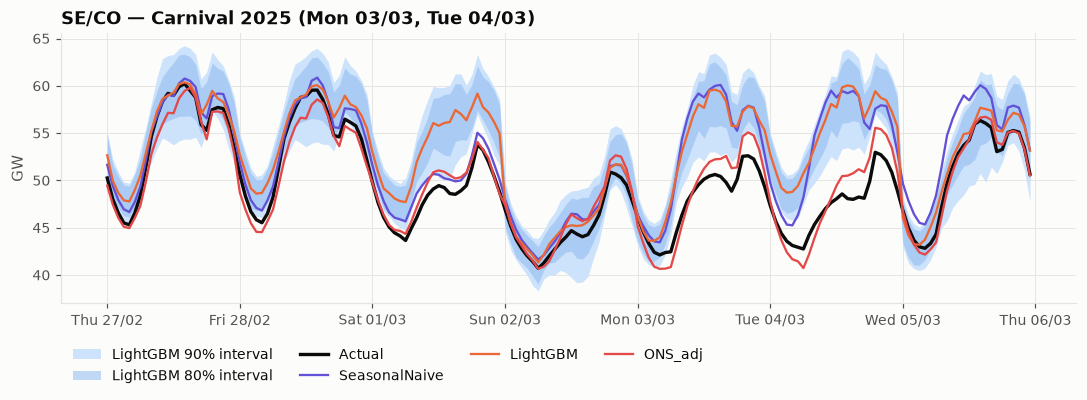

In [6]:
fig = F.actual_vs_forecast(cv, MODELS, "2025-02-27", band_model="LightGBM", title="SE/CO — Carnival 2025 (Mon 03/03, Tue 04/03)")

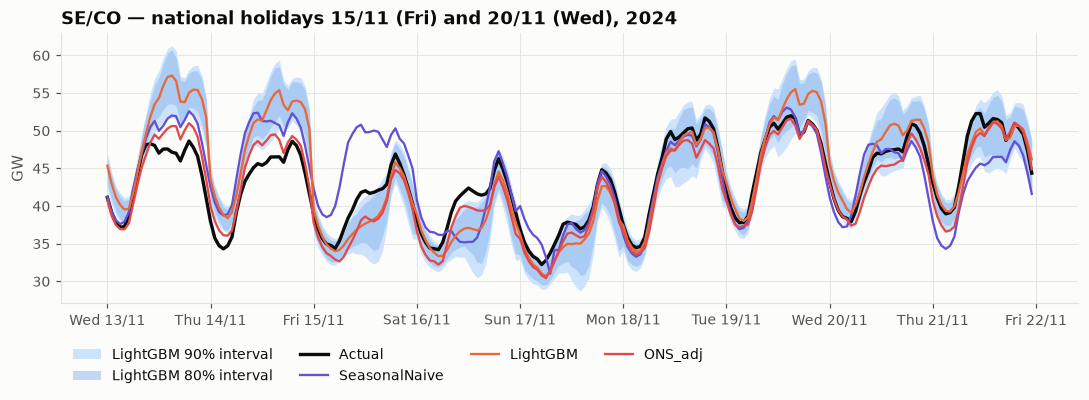

In [7]:
fig = F.actual_vs_forecast(cv, MODELS, "2024-11-13", days=9, band_model="LightGBM",
                           title="SE/CO — national holidays 15/11 (Fri) and 20/11 (Wed), 2024")

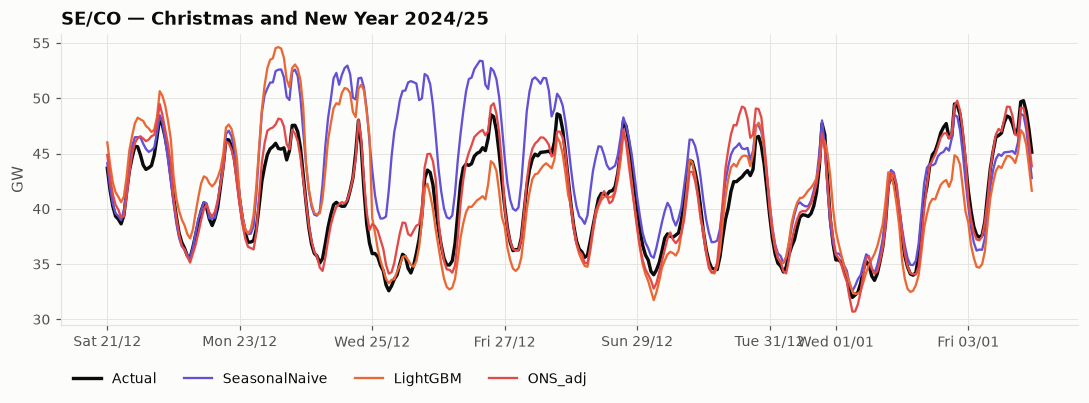

In [8]:
fig = F.actual_vs_forecast(cv, MODELS, "2024-12-21", days=14, title="SE/CO — Christmas and New Year 2024/25")

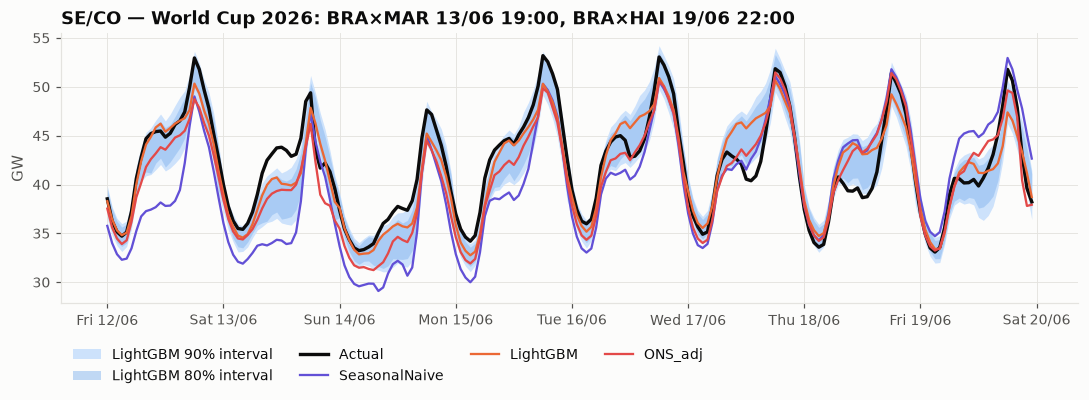

In [9]:
fig = F.actual_vs_forecast(cv, MODELS, "2026-06-12", days=8, band_model="LightGBM",
                           title="SE/CO — World Cup 2026: BRA×MAR 13/06 19:00, BRA×HAI 19/06 22:00")

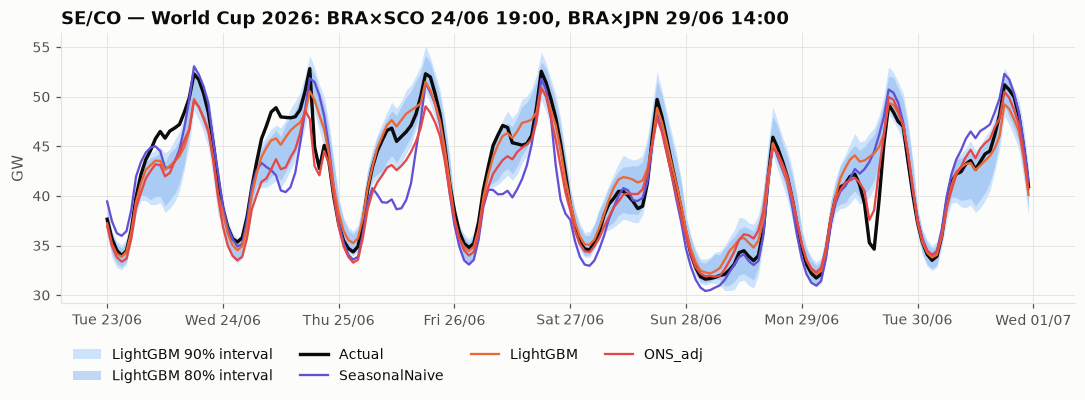

In [10]:
fig = F.actual_vs_forecast(cv, MODELS, "2026-06-23", days=8, band_model="LightGBM",
                           title="SE/CO — World Cup 2026: BRA×SCO 24/06 19:00, BRA×JPN 29/06 14:00")

## Errors by day type and by hour
Day-bootstrap 95% CIs; `n` = number of days in each segment.

In [11]:
seg = tabs["by_day_type"]
seg.pivot_table(index="day_type", columns="model", values="MAPE", observed=True).assign(
    n_days=seg.groupby("day_type", observed=True)["n_days"].max()).round(2)

model,LightGBM,ONS,ONS_adj,SeasonalNaive,n_days
day_type,,,,,
atypical_event,4.16,4.75,2.22,3.68,1
worldcup_match,3.75,4.44,3.56,7.22,6
carnival,5.45,2.42,3.24,7.34,9
national_holiday,5.64,4.23,3.02,11.13,29
state_holiday,1.85,2.11,1.74,3.81,3
bridge,5.01,3.99,2.97,8.24,8
year_end,5.76,3.52,3.82,8.16,13
normal,3.09,2.64,2.41,5.10,948


/Users/falcone/Desktop/github-repos/ONS-data-analysis/src/ons_energy/viz/forecast_plots.py:98: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  n = seg.groupby("day_type")["n_days"].max().reindex(types)


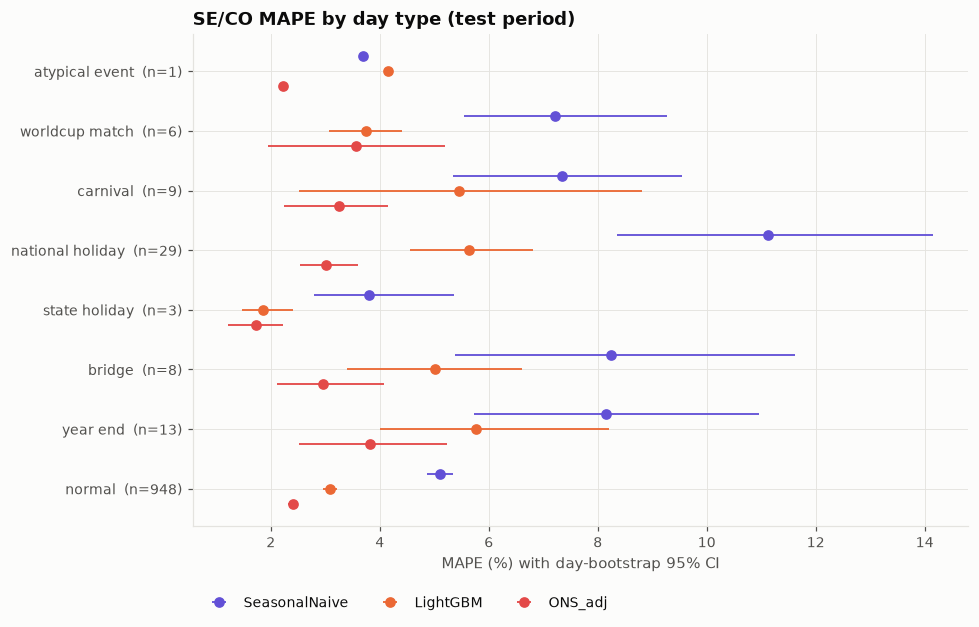

In [12]:
fig = F.mape_by_day_type(seg, MODELS, "SE/CO MAPE by day type (test period)")

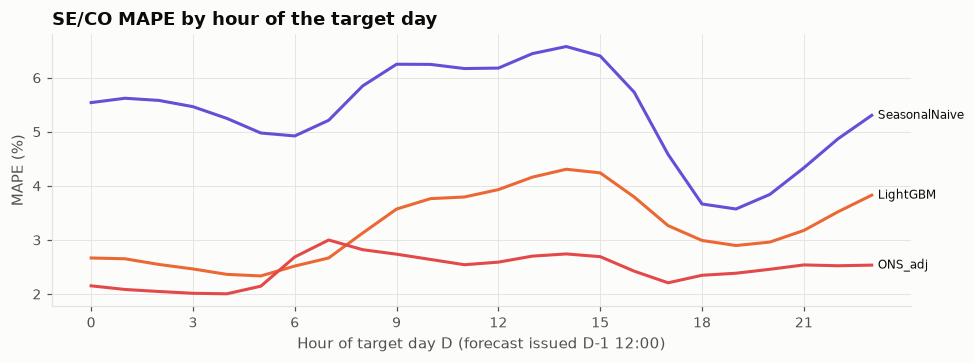

In [13]:
fig = F.mape_by_hour(tabs["by_step"], MODELS, "SE/CO MAPE by hour of the target day")

## Diebold-Mariano tests (daily MAPE; negative = better than the reference)

In [14]:
tabs["dm"].sort_values("DM")  # vs ONS programmed load

,model,vs,DM,p_value,mean_diff_pp,n_days
2,ONS_adj,ONS,-3.206,1.389e-03,-0.262,1016
1,LightGBM,ONS,3.843,1.289e-04,0.512,1016
0,SeasonalNaive,ONS,11.545,4.644e-29,2.641,1016


In [15]:
dm_table(attach_day_types(cv), "SeasonalNaive").sort_values("DM")

,model,vs,DM,p_value,mean_diff_pp,n_days
2,ONS_adj,SeasonalNaive,-13.668,3.667e-39,-2.902,1016
1,ONS,SeasonalNaive,-11.545,4.644e-29,-2.641,1016
0,LightGBM,SeasonalNaive,-10.184,2.922e-23,-2.127,1017


## Interpretability: LightGBM SHAP (normal vs special days)
Exact TreeSHAP (`pred_contrib=True`) of the one-step model trained up to the test start.

segment,normal,special
feature,,
lag1,5553.8,4144.2
lag168,763.1,705.2
hour_cos,630.3,603.0
lag2,621.0,478.2
lag24,407.4,325.7
lag336,298.9,279.8
rolling_mean_lag24_window_size168,233.3,235.4
hour_sin,221.0,201.2
rolling_mean_lag1_window_size24,203.7,136.3


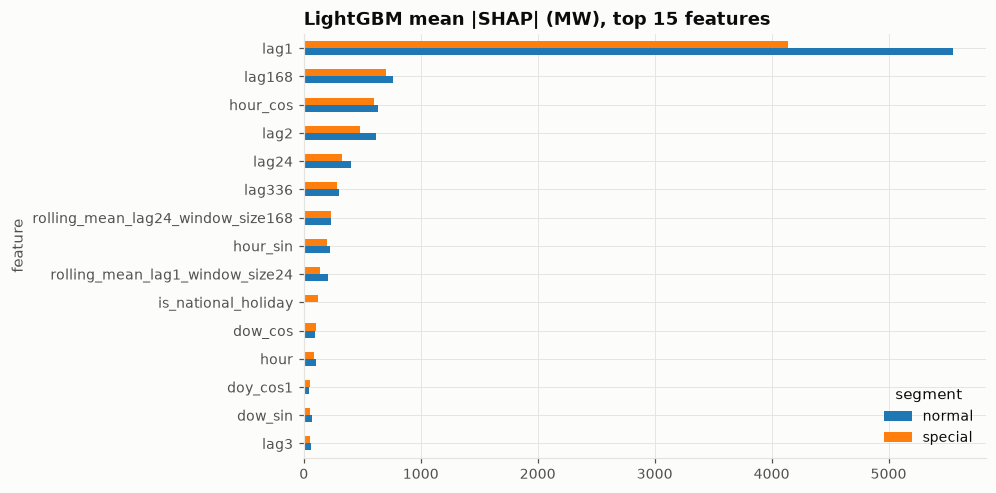

In [16]:
from ons_energy.forecast.interpret import lgbm_shap

shap = lgbm_shap(cfg, cfg.eval_end(last_full_day()))["lgbm_shap"]
top = shap.pivot_table(index="feature", columns="segment", values="mean_abs_shap").sort_values("special", ascending=False).head(15)
ax = top[::-1].plot.barh(figsize=(8, 5), title="LightGBM mean |SHAP| (MW), top 15 features")
top.round(1)

## Optional: global LightGBM on 4 subsystems and weather scenarios
`none` = no weather; `perfect` = reanalysis used as if it were a forecast (upper bound);
`honest` = forecast issued the day before (Open-Meteo previous runs, from 2022).

In [17]:
if RUN_WEATHER_ABLATION:
    SUBS = ["SE", "S", "NE", "N"]
    scenarios = {
        "none": BacktestConfig(name="global_baselines_none", subsystems=SUBS, models=[NAIVE, LGBM, ONS]),
        "perfect": BacktestConfig(name="global_lgbm_perfect", subsystems=SUBS, weather="perfect", models=[LGBM]),
        "honest": BacktestConfig(name="global_lgbm_honest", subsystems=SUBS, weather="honest", models=[LGBM]),
    }
    by_sub = {}
    for scen, c in scenarios.items():
        cv_w = run_or_load(c, retrain=RETRAIN)
        t = evaluate_backtest(cv_w, mase_scales(c), reference="ONS" if "ONS" in cv_w else None)
        if LOG_MLFLOW:
            log_backtest(c, t, cv_w)
        by_sub[scen] = t["by_subsystem"]
    fig = F.weather_ablation(by_sub)
    display(pd.concat({k: v.pivot_table(index="model", columns="unique_id", values="MAPE") for k, v in by_sub.items()}).round(2))